# Tugas Praktikum 5: Sequential Pattern Analysis
**Dataset:** Online Retail (UCI Machine Learning Repository)  
**Algoritma:** PrefixSpan

In [10]:
# Jika belum terinstall, jalankan baris di bawah ini di terminal atau uncomment:
# !uv pip install prefixspan openpyxl pandas matplotlib seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from prefixspan import PrefixSpan

import warnings
warnings.filterwarnings('ignore')

# Pengaturan tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', None)
sns.set_theme(style="whitegrid")

In [11]:
file_path = 'Online Retail.xlsx'
df = pd.read_excel(file_path)

print(f"Dimensi Dataset (Baris, Kolom): {df.shape}\n")
print("=== Informasi Struktur Dataset ===")
df.info()

print("\n=== 5 Baris Pertama Dataset ===")
display(df.head())

Dimensi Dataset (Baris, Kolom): (541909, 8)

=== Informasi Struktur Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

=== 5 Baris Pertama Dataset ===


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [12]:
rows_before = len(df)
invoices_before = df['InvoiceNo'].nunique()
customers_before = df['CustomerID'].nunique(dropna=True)

df_clean = df.copy()

df_clean = df_clean.dropna(subset=['Description'])
df_clean['Description'] = df_clean['Description'].astype(str).str.strip()
df_clean = df_clean[df_clean['Description'] != '']

df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C')]

df_clean = df_clean[df_clean['Quantity'] > 0]

df_clean = df_clean.dropna(subset=['CustomerID'])
df_clean['CustomerID'] = df_clean['CustomerID'].astype(int)

df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

rows_after = len(df_clean)
invoices_after = df_clean['InvoiceNo'].nunique()
customers_after = df_clean['CustomerID'].nunique()

summary_df = pd.DataFrame({
    'Metrik': ['Jumlah Baris', 'Jumlah Invoice Unik', 'Jumlah Pelanggan Unik (CustomerID)'],
    'Sebelum Pembersihan': [rows_before, invoices_before, customers_before],
    'Sesudah Pembersihan': [rows_after, invoices_after, customers_after],
    'Selisih (Dihapus)': [
        rows_before - rows_after,
        invoices_before - invoices_after,
        customers_before - customers_after
    ]
})

print("=== Perbandingan Data Sebelum dan Sesudah Pembersihan ===")
display(summary_df)

=== Perbandingan Data Sebelum dan Sesudah Pembersihan ===


,Metrik,Sebelum Pembersihan,Sesudah Pembersihan,Selisih (Dihapus)
0,Jumlah Baris,541909,397924,143985
1,Jumlah Invoice Unik,25900,18536,7364
2,Jumlah Pelanggan Unik (CustomerID),4372,4339,33


In [13]:
df_clean = df_clean.sort_values(by=['CustomerID', 'InvoiceDate', 'InvoiceNo'])

invoice_itemsets = (
    df_clean.groupby(['CustomerID', 'InvoiceDate', 'InvoiceNo'])['Description']
    .apply(lambda items: sorted(list(set(items))))
    .reset_index()
    .sort_values(by=['CustomerID', 'InvoiceDate'])
)

print("=== Contoh Pengelompokan Itemset per Invoice ===")
display(invoice_itemsets.head(5))

customer_sequences_itemsets = (
    invoice_itemsets.groupby('CustomerID')['Description']
    .apply(list)
    .tolist()
)

print(f"\nTotal Sequence Pelanggan Terbentuk: {len(customer_sequences_itemsets)}")
print("Contoh Sequence Pelanggan ke-1 (berisi daftar itemset per invoice):")
print(f"Jumlah transaksi (invoice): {len(customer_sequences_itemsets[0])}")
print(f"Invoice pertama (5 item pertama): {customer_sequences_itemsets[0][0][:5]}")

sequences_for_prefixspan = []
for cust_seq in customer_sequences_itemsets:
    flat_seq = [item for itemset in cust_seq for item in itemset]
    sequences_for_prefixspan.append(flat_seq)

print(f"\nData siap diproses ke PrefixSpan. Total pelanggan: {len(sequences_for_prefixspan)}")

=== Contoh Pengelompokan Itemset per Invoice ===


,CustomerID,InvoiceDate,InvoiceNo,Description
0,12346,2011-01-18 10:01:00,541431,[MEDIUM CERAMIC TOP STORAGE JAR]
1,12347,2010-12-07 14:57:00,537626,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE ORANGE, ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED, BATHROOM METAL SIGN, BLACK CANDELABRA T-LIGHT HOLDER, BLACK EAR MUFF HEADPHONES, BLACK GRAND BAROQUE PHOTO FRAME, BLUE 3 PIECE POLKADOT CUTLERY SET, BLUE DRAWER KNOB ACRYLIC EDWARDIAN, BOOM BOX SPEAKER BOYS, BOX OF 6 ASSORTED COLOUR TEASPOONS, CAMOUFLAGE EAR MUFF HEADPHONES, CLEAR DRAWER KNOB ACRYLIC EDWARDIAN, COLOUR GLASS. STAR T-LIGHT HOLDER, EMERGENCY FIRST AID TIN, FOUR HOOK WHITE LOVEBIRDS, GREEN DRAWER KNOB ACRYLIC EDWARDIAN, LARGE HEART MEASURING SPOONS, MINI PAINT SET VINTAGE, PINK 3 PIECE POLKADOT CUTLERY SET, PINK DRAWER KNOB ACRYLIC EDWARDIAN, PURPLE DRAWERKNOB ACRYLIC EDWARDIAN, RED 3 PIECE RETROSPOT CUTLERY SET, RED DRAWER KNOB ACRYLIC EDWARDIAN, RED TOADSTOOL LED NIGHT LIGHT, SET OF 2 TINS VINTAGE BATHROOM, SET/3 DECOUPAGE STACKING TINS]"
2,12347,2011-01-26 14:30:00,542237,"[3D DOG PICTURE PLAYING CARDS, 60 TEATIME FAIRY CAKE CASES, 72 SWEETHEART FAIRY CAKE CASES, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE JET SET WHITE, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELIKE GREEN, ALARM CLOCK BAKELIKE ORANGE, ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELIKE RED, BLACK CANDELABRA T-LIGHT HOLDER, BLUE NEW BAROQUE CANDLESTICK CANDLE, BOX OF 6 ASSORTED COLOUR TEASPOONS, CHOCOLATE CALCULATOR, MINI LADLE LOVE HEART RED, PACK OF 60 MUSHROOM CAKE CASES, PACK OF 60 SPACEBOY CAKE CASES, PINK NEW BAROQUECANDLESTICK CANDLE, RED RETROSPOT OVEN GLOVE, RED RETROSPOT OVEN GLOVE DOUBLE, RED TOADSTOOL LED NIGHT LIGHT, REGENCY CAKESTAND 3 TIER, SANDWICH BATH SPONGE, SET OF 2 TINS VINTAGE BATHROOM, SET/2 RED RETROSPOT TEA TOWELS, SMALL HEART MEASURING SPOONS, TEA TIME OVEN GLOVE, TOOTHPASTE TUBE PEN, WOODLAND CHARLOTTE BAG]"
3,12347,2011-04-07 10:43:00,549222,"[3D SHEET OF CAT STICKERS, 3D SHEET OF DOG STICKERS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE JET SET RED, AIRLINE BAG VINTAGE JET SET WHITE, AIRLINE BAG VINTAGE TOKYO 78, GIFT BAG PSYCHEDELIC APPLES, HOLIDAY FUN LUDO, ICE CREAM SUNDAE LIP GLOSS, LARGE HEART MEASURING SPOONS, MINI PAINT SET VINTAGE, PACK OF 60 DINOSAUR CAKE CASES, RED DRAWER KNOB ACRYLIC EDWARDIAN, RED RETROSPOT OVEN GLOVE DOUBLE, RED RETROSPOT PURSE, RED TOADSTOOL LED NIGHT LIGHT, REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACUP AND SAUCER, SET OF 2 TINS VINTAGE BATHROOM, SMALL FOLDING SCISSOR(POINTED EDGE), SMALL HEART MEASURING SPOONS, TREASURE ISLAND BOOK BOX, VINTAGE HEADS AND TAILS CARD GAME, WATERING CAN PINK BUNNY]"
4,12347,2011-06-09 13:01:00,556201,"[3D DOG PICTURE PLAYING CARDS, AIRLINE BAG VINTAGE JET SET BROWN, AIRLINE BAG VINTAGE TOKYO 78, ALARM CLOCK BAKELIKE CHOCOLATE, ALARM CLOCK BAKELIKE RED, FEATHER PEN,COAL BLACK, NAMASTE SWAGAT INCENSE, RABBIT NIGHT LIGHT, REGENCY MILK JUG PINK, REGENCY SUGAR BOWL GREEN, REGENCY TEA PLATE GREEN, REGENCY TEA PLATE PINK, REGENCY TEA PLATE ROSES, REGENCY TEA STRAINER, REGENCY TEAPOT ROSES, SMALL HEART MEASURING SPOONS, TRIPLE HOOK ANTIQUE IVORY ROSE, VICTORIAN SEWING KIT]"



Total Sequence Pelanggan Terbentuk: 4339
Contoh Sequence Pelanggan ke-1 (berisi daftar itemset per invoice):
Jumlah transaksi (invoice): 1
Invoice pertama (5 item pertama): ['MEDIUM CERAMIC TOP STORAGE JAR']

Data siap diproses ke PrefixSpan. Total pelanggan: 4339


In [14]:
total_customers = len(sequences_for_prefixspan)

def run_prefixspan_sequential(sequences_itemsets, min_sup_ratio, max_len=2):
    min_sup_count = int(np.ceil(min_sup_ratio * len(sequences_itemsets)))

    from collections import defaultdict
    item_cust_sets = defaultdict(set)
    
    for cust_idx, cust_seq in enumerate(sequences_itemsets):
        for itemset in cust_seq:
            for item in itemset:
                item_cust_sets[item].add(cust_idx)

    freq_1_items = {item: custs for item, custs in item_cust_sets.items() if len(custs) >= min_sup_count}

    filtered_sequences = []
    for cust_seq in sequences_itemsets:
        pruned_cust_seq = []
        for itemset in cust_seq:
            freq_in_invoice = [item for item in itemset if item in freq_1_items]
            if freq_in_invoice:
                pruned_cust_seq.append(freq_in_invoice)
        filtered_sequences.append(pruned_cust_seq)

    pair_counts = defaultdict(int)
    for cust_seq in filtered_sequences:
        if len(cust_seq) < 2:
            continue
        seen_pairs = set()
        suffix_items = set()
        for i in range(len(cust_seq) - 1, -1, -1):
            current_invoice_items = cust_seq[i]
            if suffix_items:
                for item_a in current_invoice_items:
                    for item_b in suffix_items:
                        seen_pairs.add((item_a, item_b))
            suffix_items.update(current_invoice_items)
            
        for pair in seen_pairs:
            pair_counts[pair] += 1
            
    freq_2_patterns = {pair: count for pair, count in pair_counts.items() if count >= min_sup_count}
    
    return min_sup_count, freq_1_items, freq_2_patterns

min_sup_1 = 0.01
count_1, freq1_001, freq2_001 = run_prefixspan_sequential(customer_sequences_itemsets, min_sup_1)

min_sup_2 = 0.02
count_2, freq1_002, freq2_002 = run_prefixspan_sequential(customer_sequences_itemsets, min_sup_2)

print(f"Total Pelanggan: {total_customers}")
print("-" * 65)
print(f"[Min Support = {min_sup_1} (Min. {count_1} pelanggan)]")
print(f"  - Jumlah Pola 1-Item (Frequent Items)      : {len(freq1_001)}")
print(f"  - Jumlah Pola Berurutan 2-Item (A -> B)    : {len(freq2_001)}")
print("-" * 65)
print(f"[Min Support = {min_sup_2} (Min. {count_2} pelanggan)]")
print(f"  - Jumlah Pola 1-Item (Frequent Items)      : {len(freq1_002)}")
print(f"  - Jumlah Pola Berurutan 2-Item (A -> B)    : {len(freq2_002)}")

Total Pelanggan: 4339
-----------------------------------------------------------------
[Min Support = 0.01 (Min. 44 pelanggan)]
  - Jumlah Pola 1-Item (Frequent Items)      : 1763
  - Jumlah Pola Berurutan 2-Item (A -> B)    : 15716
-----------------------------------------------------------------
[Min Support = 0.02 (Min. 87 pelanggan)]
  - Jumlah Pola 1-Item (Frequent Items)      : 1046
  - Jumlah Pola Berurutan 2-Item (A -> B)    : 1507


In [15]:
pruned_1d_sequences = []
for cust_seq in customer_sequences_itemsets:
    seen = set()
    seq_1d = []
    for itemset in cust_seq:
        for item in itemset:
            if item in freq1_002 and item not in seen:
                seq_1d.append(item)
                seen.add(item)
    if seq_1d:
        pruned_1d_sequences.append(seq_1d)

ps = PrefixSpan(pruned_1d_sequences)
ps_results = ps.frequent(count_2)

ps_len2 = [(freq, pat) for freq, pat in ps_results if len(pat) == 2]
print(f"Jumlah pola panjang 2 dari library PrefixSpan (min_sup=0.02): {len(ps_len2)} pola")

Jumlah pola panjang 2 dari library PrefixSpan (min_sup=0.02): 1379 pola


In [ ]:
patterns_data = []

for (item_a, item_b), sup_ab_count in freq2_001.items():
    sup_a_count = len(freq1_001[item_a])
    sup_b_count = len(freq1_001[item_b])
    
    support_a = sup_a_count / total_customers
    support_b = sup_b_count / total_customers
    support_ab = sup_ab_count / total_customers
    confidence_ab = support_ab / support_a
    
    patterns_data.append({
        'Antecedent (Item 1)': item_a,
        'Consequent (Item 2)': item_b,
        'Pola Berurutan': f"{item_a}  -->  {item_b}",
        'Jumlah Pelanggan (A -> B)': sup_ab_count,
        'Support (A)': round(support_a, 4),
        'Support (A -> B)': round(support_ab, 4),
        'Confidence (A -> B)': round(confidence_ab, 4)
    })

df_patterns = pd.DataFrame(patterns_data)

df_patterns = df_patterns.sort_values(
    by=['Support (A -> B)', 'Confidence (A -> B)'], 
    ascending=[False, False]
).reset_index(drop=True)

print(f"=== Daftar 15 Pola Berurutan Teratas (Total ditemukan: {len(df_patterns)} pola pada min_sup=0.01) ===")
display(df_patterns.head(15))

print("\n=== 3 POLA BERURUTAN TERBAIK (BERDASARKAN SUPPORT TERTINGGI) ===")
top_3_patterns = df_patterns.head(3)
display(top_3_patterns)

=== Daftar 15 Pola Berurutan Teratas (Total ditemukan: 15716 pola pada min_sup=0.01) ===


,Antecedent (Item 1),Consequent (Item 2),Pola Berurutan,Jumlah Pelanggan (A -> B),Support (A),Support (A -> B),Confidence (A -> B)
0,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER --> WHITE HANGING HEART T-LIGHT HOLDER,405,0.1973,0.0933,0.4731
1,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER --> REGENCY CAKESTAND 3 TIER,330,0.2030,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT --> JUMBO BAG RED RETROSPOT,312,0.1463,0.0719,0.4913
3,ASSORTED COLOUR BIRD ORNAMENT,ASSORTED COLOUR BIRD ORNAMENT,ASSORTED COLOUR BIRD ORNAMENT --> ASSORTED COLOUR BIRD ORNAMENT,291,0.1563,0.0671,0.4292
4,PARTY BUNTING,PARTY BUNTING,PARTY BUNTING --> PARTY BUNTING,280,0.1632,0.0645,0.3955
5,LUNCH BAG RED RETROSPOT,LUNCH BAG RED RETROSPOT,LUNCH BAG RED RETROSPOT --> LUNCH BAG RED RETROSPOT,276,0.1226,0.0636,0.5188
6,LUNCH BAG BLACK SKULL.,LUNCH BAG BLACK SKULL.,LUNCH BAG BLACK SKULL. --> LUNCH BAG BLACK SKULL.,229,0.1056,0.0528,0.5000
7,SET OF 3 CAKE TINS PANTRY DESIGN,SET OF 3 CAKE TINS PANTRY DESIGN,SET OF 3 CAKE TINS PANTRY DESIGN --> SET OF 3 CAKE TINS PANTRY DESIGN,225,0.1475,0.0519,0.3516
8,LUNCH BAG RED RETROSPOT,LUNCH BAG BLACK SKULL.,LUNCH BAG RED RETROSPOT --> LUNCH BAG BLACK SKULL.,212,0.1226,0.0489,0.3985
9,LUNCH BAG CARS BLUE,LUNCH BAG RED RETROSPOT,LUNCH BAG CARS BLUE --> LUNCH BAG RED RETROSPOT,209,0.1104,0.0482,0.4363



=== 3 POLA BERURUTAN TERBAIK (BERDASARKAN SUPPORT TERTINGGI) ===


,Antecedent (Item 1),Consequent (Item 2),Pola Berurutan,Jumlah Pelanggan (A -> B),Support (A),Support (A -> B),Confidence (A -> B)
0,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER,WHITE HANGING HEART T-LIGHT HOLDER --> WHITE HANGING HEART T-LIGHT HOLDER,405,0.1973,0.0933,0.4731
1,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER,REGENCY CAKESTAND 3 TIER --> REGENCY CAKESTAND 3 TIER,330,0.2030,0.0761,0.3746
2,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT,JUMBO BAG RED RETROSPOT --> JUMBO BAG RED RETROSPOT,312,0.1463,0.0719,0.4913


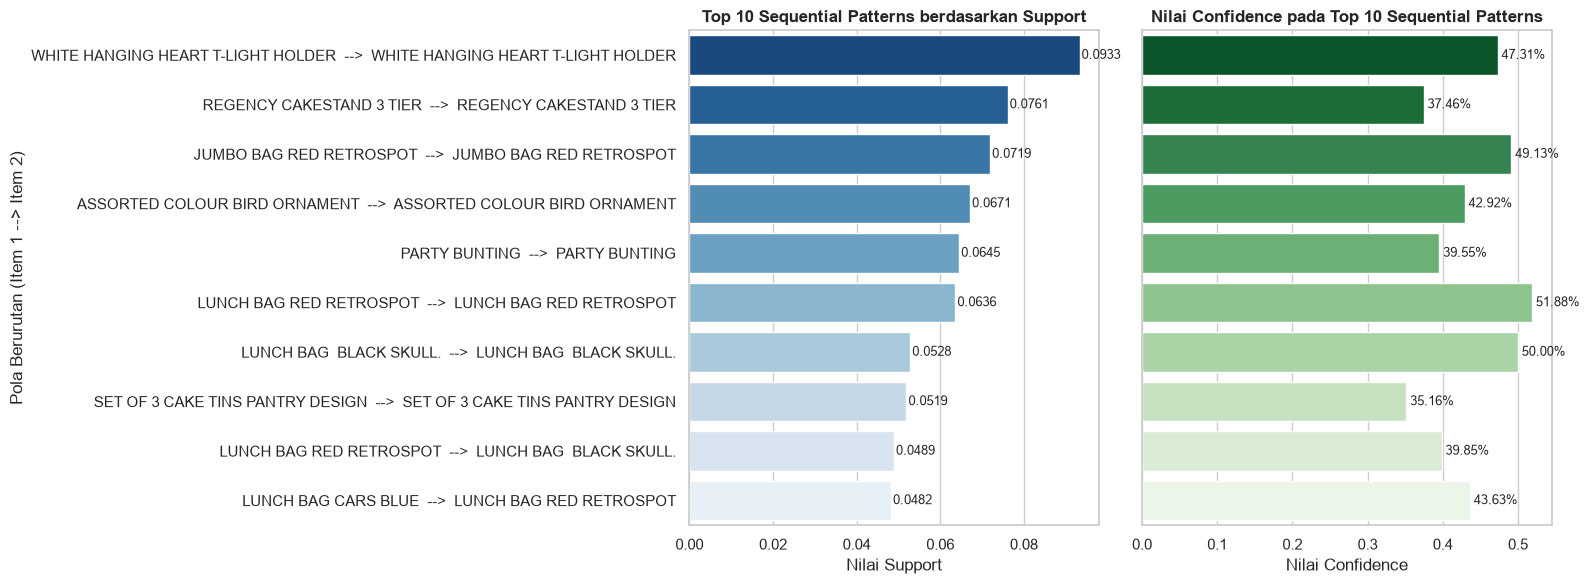

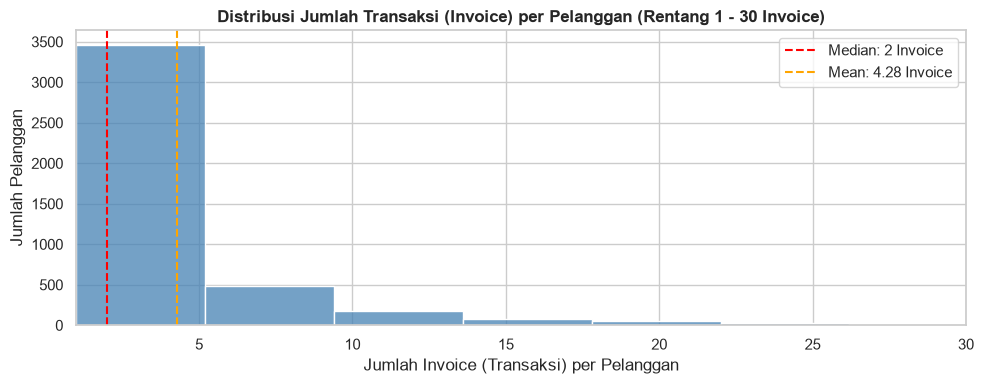

In [ ]:
top_10 = df_patterns.head(10).copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

sns.barplot(
    data=top_10, 
    x='Support (A -> B)', 
    y='Pola Berurutan', 
    ax=axes[0], 
    palette='Blues_r'
)
axes[0].set_title('Top 10 Sequential Patterns berdasarkan Support', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Nilai Support')
axes[0].set_ylabel('Pola Berurutan (Item 1 --> Item 2)')
for i, v in enumerate(top_10['Support (A -> B)']):
    axes[0].text(v + 0.0005, i, f"{v:.4f}", va='center', fontsize=9)

sns.barplot(
    data=top_10, 
    x='Confidence (A -> B)', 
    y='Pola Berurutan', 
    ax=axes[1], 
    palette='Greens_r'
)
axes[1].set_title('Nilai Confidence pada Top 10 Sequential Patterns', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Nilai Confidence')
axes[1].set_ylabel('')
for i, v in enumerate(top_10['Confidence (A -> B)']):
    axes[1].text(v + 0.005, i, f"{v:.2%}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

invoice_counts_per_cust = [len(seq) for seq in customer_sequences_itemsets]
plt.figure(figsize=(10, 4))
sns.histplot(invoice_counts_per_cust, bins=50, kde=False, color='steelblue')
plt.xlim(1, 30)
plt.title('Distribusi Jumlah Transaksi (Invoice) per Pelanggan (Rentang 1 - 30 Invoice)', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Invoice (Transaksi) per Pelanggan')
plt.ylabel('Jumlah Pelanggan')
plt.axvline(np.median(invoice_counts_per_cust), color='red', linestyle='--', label=f'Median: {np.median(invoice_counts_per_cust):.0f} Invoice')
plt.axvline(np.mean(invoice_counts_per_cust), color='orange', linestyle='--', label=f'Mean: {np.mean(invoice_counts_per_cust):.2f} Invoice')
plt.legend()
plt.tight_layout()
plt.show()